In [10]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

sessions = pd.read_csv("../data/raw/sessions.csv")
events = pd.read_csv("../data/raw/events.csv")

print("Sessions shape:", sessions.shape)
print("Events shape:", events.shape)

display(sessions.head())
display(events.head())

Sessions shape: (10000, 11)
Events shape: (30913, 8)


,session_id,customer_id,session_start,device_type,product_id,product_category,product_price,quantity,discount_pct,shipping_charge,cart_id
0,S00001,C07463,2026-10-28 21:44:54,Desktop,P0259,Home & Kitchen,11319.54,1,0,0,CART00001
1,S00002,C02242,2026-10-23 23:08:05,Mobile,P0471,Home & Kitchen,13866.27,1,0,0,CART00002
2,S00003,C03909,2026-10-07 09:58:13,Desktop,P0044,Fashion,4175.46,2,5,79,NaN
3,S00004,C00317,2026-10-31 20:52:48,Desktop,P0385,Fashion,1498.63,2,10,79,CART00004
4,S00005,C01337,2026-10-31 18:32:43,Mobile,P0280,Electronics,51483.23,1,0,0,CART00005


,event_id,session_id,event_name,event_timestamp,payment_method,payment_status,payment_failure_reason,order_id
0,E0000001,S00001,product_view,2026-10-28 21:44:54,NaN,NaN,NaN,NaN
1,E0000002,S00001,add_to_cart,2026-10-28 21:47:54,NaN,NaN,NaN,NaN
2,E0000003,S00002,product_view,2026-10-23 23:08:05,NaN,NaN,NaN,NaN
3,E0000004,S00002,add_to_cart,2026-10-23 23:14:05,NaN,NaN,NaN,NaN
4,E0000005,S00003,product_view,2026-10-07 09:58:13,NaN,NaN,NaN,NaN


In [5]:
print("Sessions:", sessions.shape)
print("Events:", events.shape)

print("\nSession columns:")
print(sessions.columns.tolist())

print("\nEvent columns:")
print(events.columns.tolist())

Sessions: (10000, 11)
Events: (30913, 8)

Session columns:
['session_id', 'customer_id', 'session_start', 'device_type', 'product_id', 'product_category', 'product_price', 'quantity', 'discount_pct', 'shipping_charge', 'cart_id']

Event columns:
['event_id', 'session_id', 'event_name', 'event_timestamp', 'payment_method', 'payment_status', 'payment_failure_reason', 'order_id']


In [6]:
print("SESSIONS DATA")
sessions.info()

print("\nEVENTS DATA")
events.info()

SESSIONS DATA
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   session_id        10000 non-null  str    
 1   customer_id       10000 non-null  str    
 2   session_start     10000 non-null  str    
 3   device_type       10000 non-null  str    
 4   product_id        10000 non-null  str    
 5   product_category  10000 non-null  str    
 6   product_price     10000 non-null  float64
 7   quantity          10000 non-null  int64  
 8   discount_pct      10000 non-null  int64  
 9   shipping_charge   10000 non-null  int64  
 10  cart_id           6969 non-null   str    
dtypes: float64(1), int64(3), str(7)
memory usage: 859.5 KB

EVENTS DATA
<class 'pandas.DataFrame'>
RangeIndex: 30913 entries, 0 to 30912
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   e

In [7]:
print("Missing values in Sessions:")
print(sessions.isnull().sum())

print("\nMissing values in Events:")
print(events.isnull().sum())

print("\nDuplicate rows in Sessions:", sessions.duplicated().sum())
print("Duplicate rows in Events:", events.duplicated().sum())

Missing values in Sessions:
session_id             0
customer_id            0
session_start          0
device_type            0
product_id             0
product_category       0
product_price          0
quantity               0
discount_pct           0
shipping_charge        0
cart_id             3031
dtype: int64

Missing values in Events:
event_id                      0
session_id                    0
event_name                    0
event_timestamp               0
payment_method            22459
payment_status            22459
payment_failure_reason    30567
order_id                  26859
dtype: int64

Duplicate rows in Sessions: 0
Duplicate rows in Events: 0


Funnel Analysis

In [8]:
funnel = events.groupby("event_name")["session_id"].nunique()

stages = [
    "product_view",
    "add_to_cart",
    "checkout_initiated",
    "payment_initiated",
    "purchase_completed"
]

for stage in stages:
    print(stage, ":", funnel.get(stage, 0))

product_view : 10000
add_to_cart : 6969
checkout_initiated : 5490
payment_initiated : 4400
purchase_completed : 4054


In [9]:
for i in range(len(stages) - 1):

    current = funnel.get(stages[i], 0)
    next_stage = funnel.get(stages[i + 1], 0)

    conversion = (next_stage / current) * 100
    dropoff = 100 - conversion

    print(f"\n{stages[i]} -> {stages[i+1]}")
    print("Conversion Rate:", round(conversion, 2), "%")
    print("Drop-off Rate:", round(dropoff, 2), "%")


product_view -> add_to_cart
Conversion Rate: 69.69 %
Drop-off Rate: 30.31 %

add_to_cart -> checkout_initiated
Conversion Rate: 78.78 %
Drop-off Rate: 21.22 %

checkout_initiated -> payment_initiated
Conversion Rate: 80.15 %
Drop-off Rate: 19.85 %

payment_initiated -> purchase_completed
Conversion Rate: 92.14 %
Drop-off Rate: 7.86 %


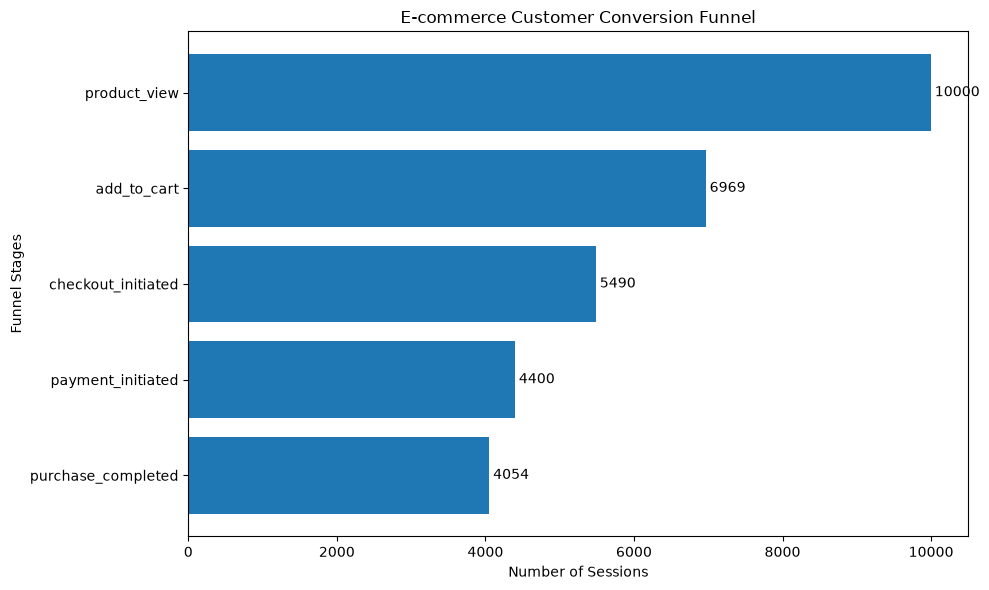

In [13]:
counts = [funnel.get(stage, 0) for stage in stages]

plt.figure(figsize=(10, 6))

plt.barh(stages, counts)

plt.xlabel("Number of Sessions")
plt.ylabel("Funnel Stages")
plt.title("E-commerce Customer Conversion Funnel")

plt.gca().invert_yaxis()

for i, count in enumerate(counts):
    plt.text(count + 50, i, str(count), va='center')

plt.tight_layout()
plt.show()

Device-wise Conversion Analysis

In [14]:
device_counts = sessions["device_type"].value_counts()
print(device_counts)

device_type
Mobile     6048
Desktop    2967
Tablet      985
Name: count, dtype: int64


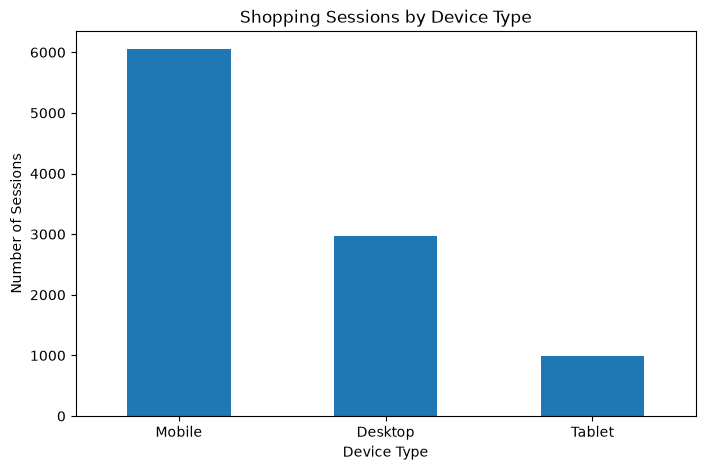

In [15]:
device_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Shopping Sessions by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)

plt.show()

In [16]:
# Merge sessions with events

merged = events.merge(
    sessions[["session_id", "device_type"]],
    on="session_id",
    how="left"
)

# Find sessions that added products to cart
cart_sessions = merged[
    merged["event_name"] == "add_to_cart"
]

# Find sessions that completed purchases
purchase_sessions = merged[
    merged["event_name"] == "purchase_completed"
]

# Calculate device-wise cart sessions
cart_by_device = cart_sessions.groupby(
    "device_type"
)["session_id"].nunique()

# Calculate device-wise purchase sessions
purchase_by_device = purchase_sessions.groupby(
    "device_type"
)["session_id"].nunique()

# Calculate abandonment rate
device_analysis = pd.DataFrame({
    "Cart Sessions": cart_by_device,
    "Purchase Sessions": purchase_by_device
}).fillna(0)

device_analysis["Abandoned Sessions"] = (
    device_analysis["Cart Sessions"] -
    device_analysis["Purchase Sessions"]
)

device_analysis["Abandonment Rate (%)"] = (
    device_analysis["Abandoned Sessions"] /
    device_analysis["Cart Sessions"] * 100
)

display(device_analysis.round(2))

,Cart Sessions,Purchase Sessions,Abandoned Sessions,Abandonment Rate (%)
device_type,,,,
Desktop,2171,1372,799,36.80
Mobile,4101,2240,1861,45.38
Tablet,697,442,255,36.59


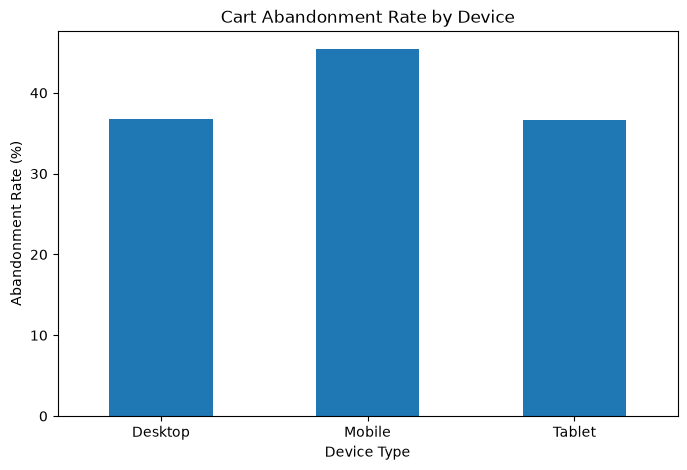

In [17]:
device_analysis["Abandonment Rate (%)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Cart Abandonment Rate by Device")
plt.xlabel("Device Type")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=0)

plt.show()

Product Category-wise Cart Abandonment

In [18]:
merged_category = events.merge(
    sessions[["session_id", "product_category"]],
    on="session_id",
    how="left"
)

category_cart = merged_category[
    merged_category["event_name"] == "add_to_cart"
]

category_purchase = merged_category[
    merged_category["event_name"] == "purchase_completed"
]

cart_by_category = category_cart.groupby(
    "product_category"
)["session_id"].nunique()

purchase_by_category = category_purchase.groupby(
    "product_category"
)["session_id"].nunique()

category_analysis = pd.DataFrame({
    "Cart Sessions": cart_by_category,
    "Purchase Sessions": purchase_by_category
}).fillna(0)

category_analysis["Abandoned Sessions"] = (
    category_analysis["Cart Sessions"] -
    category_analysis["Purchase Sessions"]
)

category_analysis["Abandonment Rate (%)"] = (
    category_analysis["Abandoned Sessions"] /
    category_analysis["Cart Sessions"] * 100
)

display(category_analysis.round(2))

,Cart Sessions,Purchase Sessions,Abandoned Sessions,Abandonment Rate (%)
product_category,,,,
Beauty,1324,766,558,42.15
Electronics,1387,778,609,43.91
Fashion,1943,1173,770,39.63
Home & Kitchen,1467,855,612,41.72
Sports,848,482,366,43.16


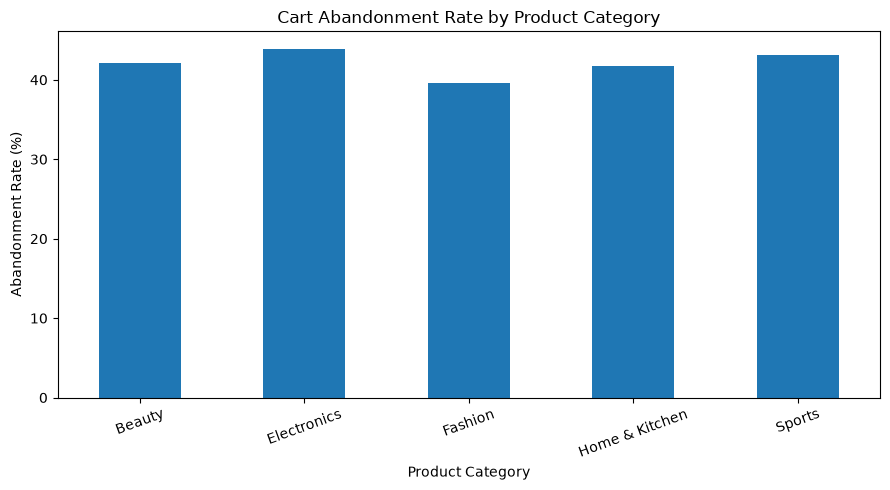

In [19]:
category_analysis["Abandonment Rate (%)"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Cart Abandonment Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Payment Method Analysis

In [20]:
payment_data = events[
    events["event_name"] == "payment_initiated"
]

payment_method_counts = payment_data.groupby(
    "payment_method"
)["session_id"].nunique()

print(payment_method_counts)

payment_method
COD             798
Card           1212
Net Banking     489
UPI            1901
Name: session_id, dtype: int64


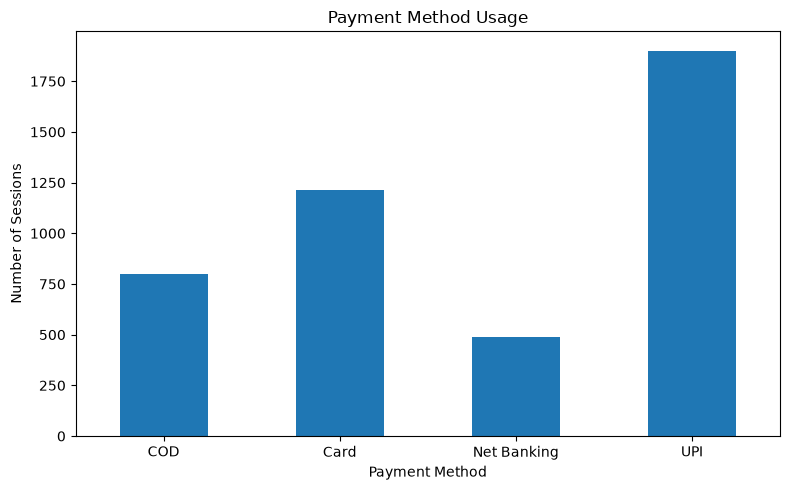

In [21]:
payment_method_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Payment Method Usage")
plt.xlabel("Payment Method")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Payment Failure Analysis

In [22]:
payment_data = events[
    events["event_name"] == "payment_initiated"
]

payment_status_counts = payment_data["payment_status"].value_counts()

print(payment_status_counts)

payment_status
Successful    4054
Failed         346
Name: count, dtype: int64


In [23]:
total_payments = payment_status_counts.sum()
failed_payments = payment_status_counts.get("Failed", 0)

failure_rate = (failed_payments / total_payments) * 100

print("Total Payments:", total_payments)
print("Failed Payments:", failed_payments)
print("Payment Failure Rate:", round(failure_rate, 2), "%")

Total Payments: 4400
Failed Payments: 346
Payment Failure Rate: 7.86 %


Payment Failure Reason Analysis

In [24]:
failed_payment_data = payment_data[
    payment_data["payment_status"] == "Failed"
]

print(failed_payment_data["payment_failure_reason"].value_counts())

payment_failure_reason
Bank declined transaction    100
Authentication failed         89
Payment timeout               79
Insufficient funds            78
Name: count, dtype: int64


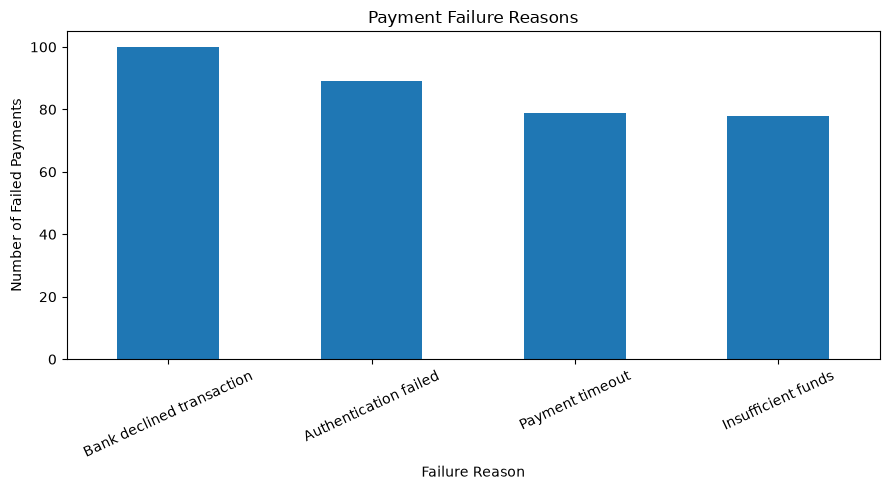

In [25]:
failure_reasons = failed_payment_data[
    "payment_failure_reason"
].value_counts()

failure_reasons.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Payment Failure Reasons")
plt.xlabel("Failure Reason")
plt.ylabel("Number of Failed Payments")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [26]:
failure_reasons = failed_payment_data[
    "payment_failure_reason"
].value_counts()

failure_percentage = (
    failure_reasons / failure_reasons.sum()
) * 100

print(failure_percentage.round(2))

payment_failure_reason
Bank declined transaction    28.90
Authentication failed        25.72
Payment timeout              22.83
Insufficient funds           22.54
Name: count, dtype: float64


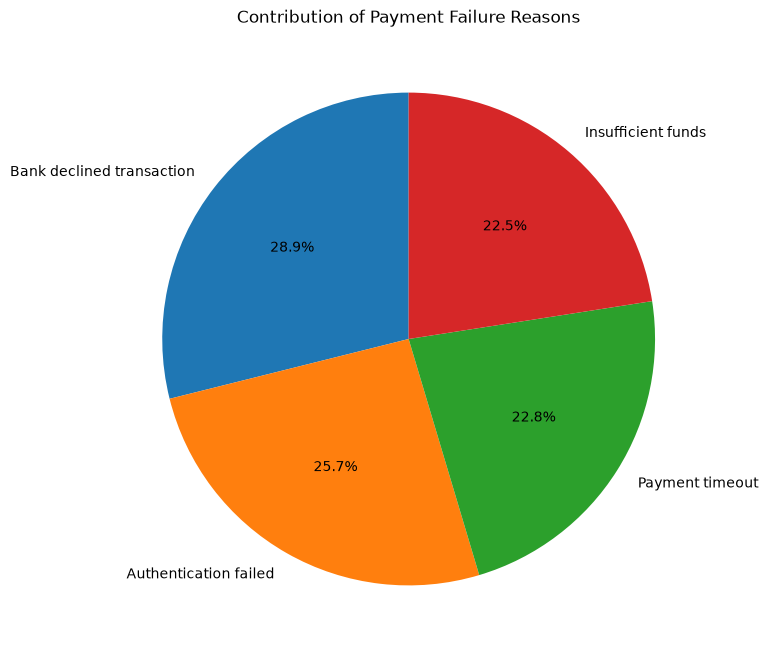

In [27]:
failure_reasons.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(8, 8),
    startangle=90
)

plt.title("Contribution of Payment Failure Reasons")
plt.ylabel("")
plt.show()

Time-based Cart Abandonment Analysis

In [28]:
sessions["session_start"] = pd.to_datetime(
    sessions["session_start"]
)

sessions["hour"] = sessions["session_start"].dt.hour

hourly_sessions = sessions["hour"].value_counts().sort_index()

print(hourly_sessions)

hour
0     402
1     406
2     379
3     436
4     420
5     417
6     418
7     397
8     450
9     450
10    416
11    429
12    432
13    409
14    414
15    417
16    384
17    413
18    422
19    410
20    424
21    414
22    422
23    419
Name: count, dtype: int64


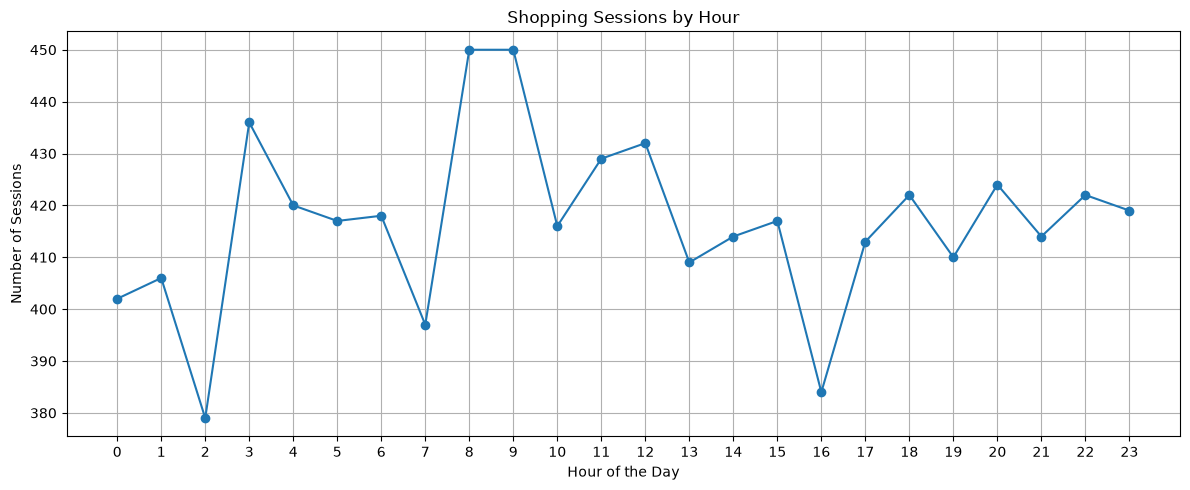

In [29]:
hourly_sessions.plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Shopping Sessions by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Sessions")
plt.xticks(range(24))
plt.grid()
plt.tight_layout()
plt.show()

In [31]:
time_merged = events.merge(
    sessions[["session_id", "hour"]],
    on="session_id",
    how="left"
)

hourly_cart = time_merged[
    time_merged["event_name"] == "add_to_cart"
]

hourly_purchase = time_merged[
    time_merged["event_name"] == "purchase_completed"
]

In [32]:
cart_by_hour = hourly_cart.groupby("hour")["session_id"].nunique()

purchase_by_hour = hourly_purchase.groupby("hour")["session_id"].nunique()

hourly_analysis = pd.DataFrame({
    "Cart Sessions": cart_by_hour,
    "Purchase Sessions": purchase_by_hour
}).fillna(0)

hourly_analysis["Abandoned Sessions"] = (
    hourly_analysis["Cart Sessions"] -
    hourly_analysis["Purchase Sessions"]
)

hourly_analysis["Abandonment Rate (%)"] = (
    hourly_analysis["Abandoned Sessions"] /
    hourly_analysis["Cart Sessions"] * 100
)

display(hourly_analysis.round(2))

,Cart Sessions,Purchase Sessions,Abandoned Sessions,Abandonment Rate (%)
hour,,,,
0,293,156,137,46.76
1,297,163,134,45.12
2,266,144,122,45.86
3,303,178,125,41.25
4,305,180,125,40.98
5,293,160,133,45.39
6,292,178,114,39.04
7,267,157,110,41.20
8,319,193,126,39.50


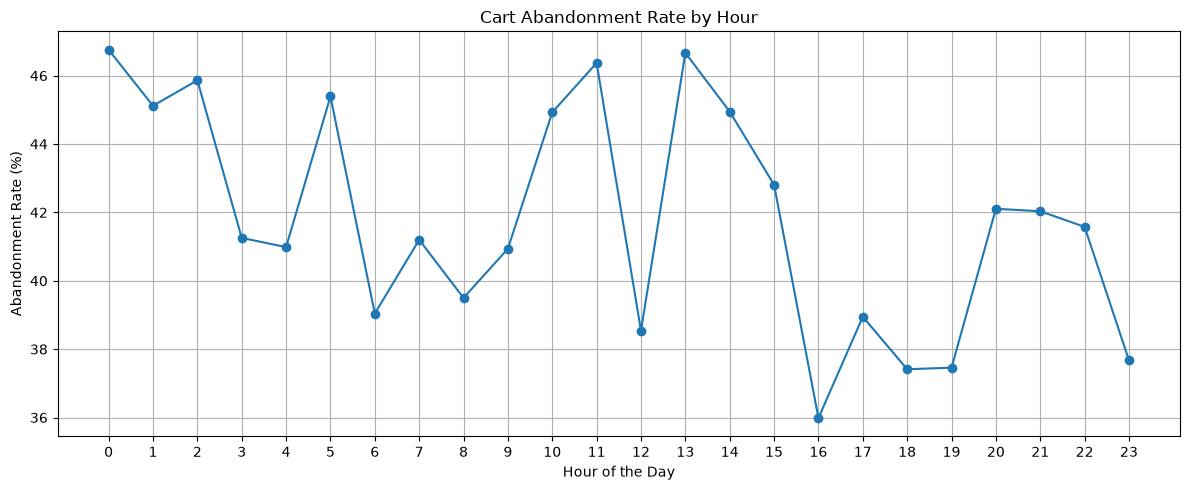

In [33]:
hourly_analysis["Abandonment Rate (%)"].plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)

plt.title("Cart Abandonment Rate by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Abandonment Rate (%)")
plt.xticks(range(24))
plt.grid()
plt.tight_layout()
plt.show()

In [34]:
highest_hour = hourly_analysis["Abandonment Rate (%)"].idxmax()
lowest_hour = hourly_analysis["Abandonment Rate (%)"].idxmin()

print("Highest abandonment hour:", highest_hour)
print("Highest rate:", hourly_analysis["Abandonment Rate (%)"].max(), "%")

print("Lowest abandonment hour:", lowest_hour)
print("Lowest rate:", hourly_analysis["Abandonment Rate (%)"].min(), "%")

Highest abandonment hour: 0
Highest rate: 46.75767918088737 %
Lowest abandonment hour: 16
Lowest rate: 35.98326359832636 %
